# 05 · Pipeline cuối và phân tích lỗi — TV1
Không chọn lại thuật toán theo test. Kết quả phản ánh SOS oil/background, không đo nhầm lẫn riêng vùng gió yếu, màng sinh học, mưa.

In [1]:
from pathlib import Path
import sys, json
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from sar_oil import core, reference
from sar_oil.data import records, read_pair, MANIFEST
from sar_oil.experiments import OUT
def table(rows, columns):
    def value(x): return (f'{x:.3e}' if 0<abs(x)<1e-4 else f'{x:.6f}') if isinstance(x,float) else str(x)
    display(HTML('<table><tr>'+''.join('<th>'+c+'</th>' for c in columns)+'</tr>'+''.join('<tr>'+''.join('<td>'+value(r.get(c,''))+'</td>' for c in columns)+'</tr>' for r in rows)+'</table>'))
def load(name):
    p=OUT/name
    if not p.exists(): raise FileNotFoundError(f'Missing {p}. Run python scripts/sos.py reproduce first.')
    return json.loads(p.read_text(encoding='utf-8'))


In [2]:
evaluation=load('evaluation.json')
table([dict(experiment=k,**v['metrics'],seconds=v['seconds']) for k,v in evaluation.items() if k!='provenance'],['experiment','images','precision','recall','f1','pixel_iou','fp_per_image','seconds'])
print('Provenance:',evaluation['provenance'])

experiment,images,precision,recall,f1,pixel_iou,fp_per_image,seconds
test_final,839,0.254146,0.313011,0.280524,0.661391,3.483909,42.108540
test_baseline,839,0.008587,0.133878,0.016139,0.436663,58.619785,90.461442
test_no_classifier,839,0.075335,0.319925,0.121953,0.586725,14.892729,48.302703
palsar_val,776,0.384677,0.360791,0.372351,0.642321,2.970361,41.185623
validation_label64,671,0.317858,0.377990,0.345326,0.652623,3.284650,36.880392
validation_label128,671,0.314454,0.370803,0.340312,0.652354,3.301043,36.272951
validation_label192,671,0.312597,0.365677,0.337060,0.651695,3.309985,41.831941


Provenance: {'python': '3.13.5', 'packages': {'numpy': '2.5.4', 'scipy': '1.18.1', 'scikit-image': '0.26.0', 'scikit-learn': '1.9.1', 'Pillow': '13.0.0'}, 'seed': 2026, 'manifest_sha256': '572d38f21c25a628d419181d108f50e6e43ebd52cb9b85368f4cd4771c9bed7e', 'selected_id': 'b09dd86237118107_all_svm_4e452bd6650829fb', 'workers': 6}


TP được ghép một-một với IoU >=0.5, ưu tiên số cặp rồi tổng IoU. Báo F1 micro, không trung bình F1 từng ảnh. Baseline và bỏ classifier là ablation; PALSAR chỉ đánh giá ngoài miền với cấu hình đóng băng. Không giả lập góc tới hoặc gió.

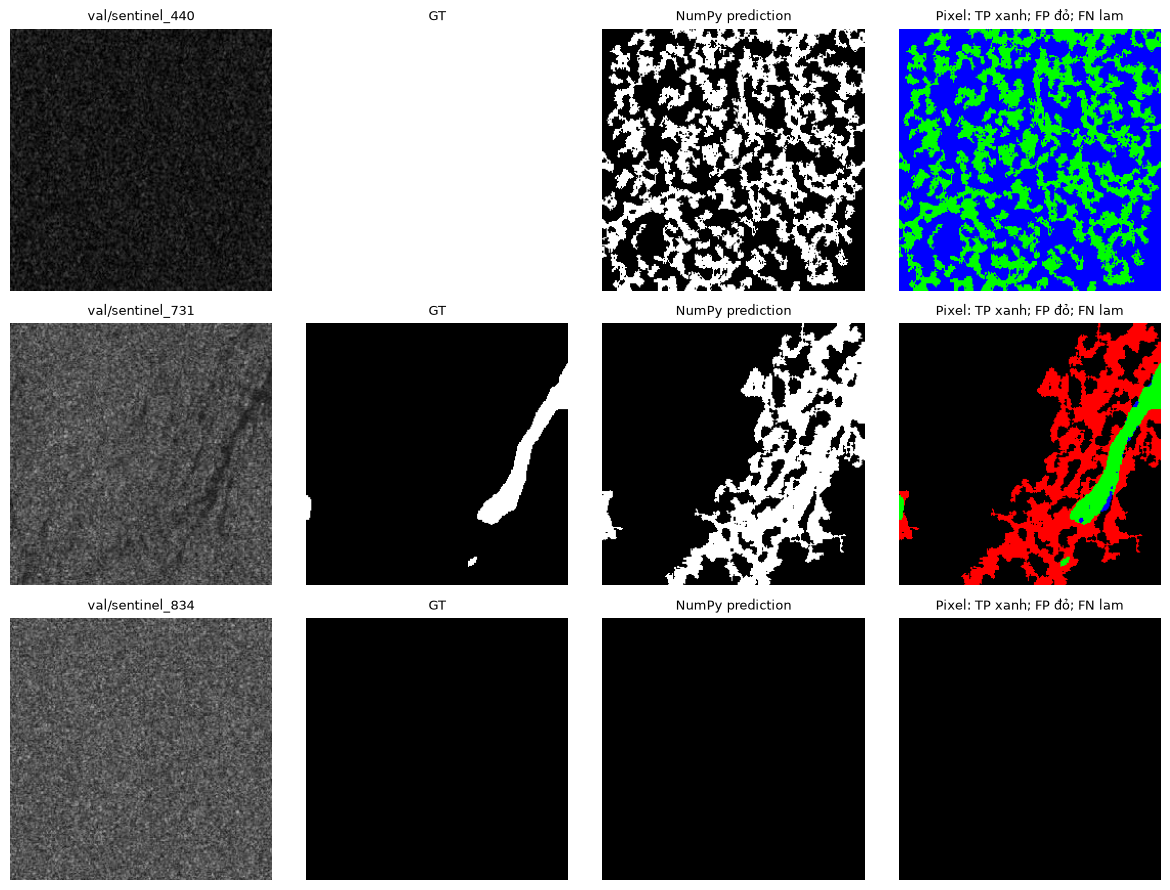

In [3]:
from sar_oil.models import RegionModel
from sar_oil.pipeline import predict
selected=load('selected.json'); model=RegionModel.load(OUT/selected['model_file'])
per=evaluation['test_final']['per_image']; ordered=sorted(per,key=lambda r:r['counts']['fp']+r['counts']['fn'],reverse=True)
by_id={r['id']:r for r in records('test')}; chosen=[ordered[0],ordered[len(ordered)//2],ordered[-1]]
fig,axes=plt.subplots(3,4,figsize=(12,9))
for i,row in enumerate(chosen):
    a,g=read_pair(by_id[row['id']]); p,regions=predict(a,selected['config'],model)
    errors=np.zeros((*g.shape,3)); errors[p&g]=[0,1,0]; errors[p&~g]=[1,0,0]; errors[~p&g]=[0,0,1]
    for ax,img,title in zip(axes[i],[a,g,p,errors],[row['id'],'GT','NumPy prediction','Pixel: TP xanh; FP đỏ; FN lam']): ax.imshow(img,cmap='gray',vmin=0,vmax=1); ax.set_title(title,fontsize=9); ax.axis('off')
plt.tight_layout(); plt.show()

Chạy lại toàn bộ số liệu: `python scripts/sos.py reproduce --workers 6`. Notebook đọc kết quả benchmark đã thực thi và chạy trực tiếp các ví dụ, không tự khởi động lại hàng trăm thí nghiệm khi Run All. Xem giao thức trong docs/GIAO_THUC_THUC_NGHIEM.md.

## Ba ca thất bại và độ phân tán trên toàn tập
Chạy `python scripts/analyze_failures.py` để tái tạo. Các ca được chọn theo ba tiêu chí lỗi đã công bố, không dùng để thay mô hình. Macro chỉ tính các ảnh có mẫu số xác định; micro vẫn là chỉ số chính.

Nhánh thích nghi bổ sung (chỉ validation): {'filter': {'name': 'lee', 'size': 7, 'looks': 1}, 'threshold': {'name': 'niblack', 'size': 51, 'k': 0.2}, 'morphology': {'operation': 'none', 'min_area': 64}} cart {'max_depth': 3, 'min_leaf': 5}
F1 adaptive validation: 0.14465611882466903 ; không dùng kết quả test Otsu cho nhánh này.


experiment,micro_f1,mean,std_population,defined,undefined
test_final,0.280524,0.349124,0.317278,814,25
test_baseline,0.016139,0.028920,0.062911,839,0
test_no_classifier,0.121953,0.229203,0.254032,839,0
palsar_val,0.372351,0.412061,0.311667,734,42
validation_label64,0.345326,0.422550,0.348488,647,24
validation_label128,0.340312,0.421836,0.348557,646,25
validation_label192,0.337060,0.420273,0.349383,646,25


val/sentinel_440 largest_false_positive_count
Proposal: {'tp': 0, 'fp': 35, 'fn': 1, 'images': 1, 'empty_images': 0, 'intersection': 26135, 'union': 65536, 'predicted_pixels': 26135, 'truth_pixels': 65536, 'edge_gt': 1, 'edge_tp': 0, 'interior_gt': 0, 'interior_tp': 0} Final: {'tp': 0, 'fp': 35, 'fn': 1, 'images': 1, 'empty_images': 0, 'intersection': 26135, 'union': 65536, 'predicted_pixels': 26135, 'truth_pixels': 65536, 'edge_gt': 1, 'edge_tp': 0, 'interior_gt': 0, 'interior_tp': 0}
GT pixels absent from proposals: 39401 GT pixels removed by classifier: 0


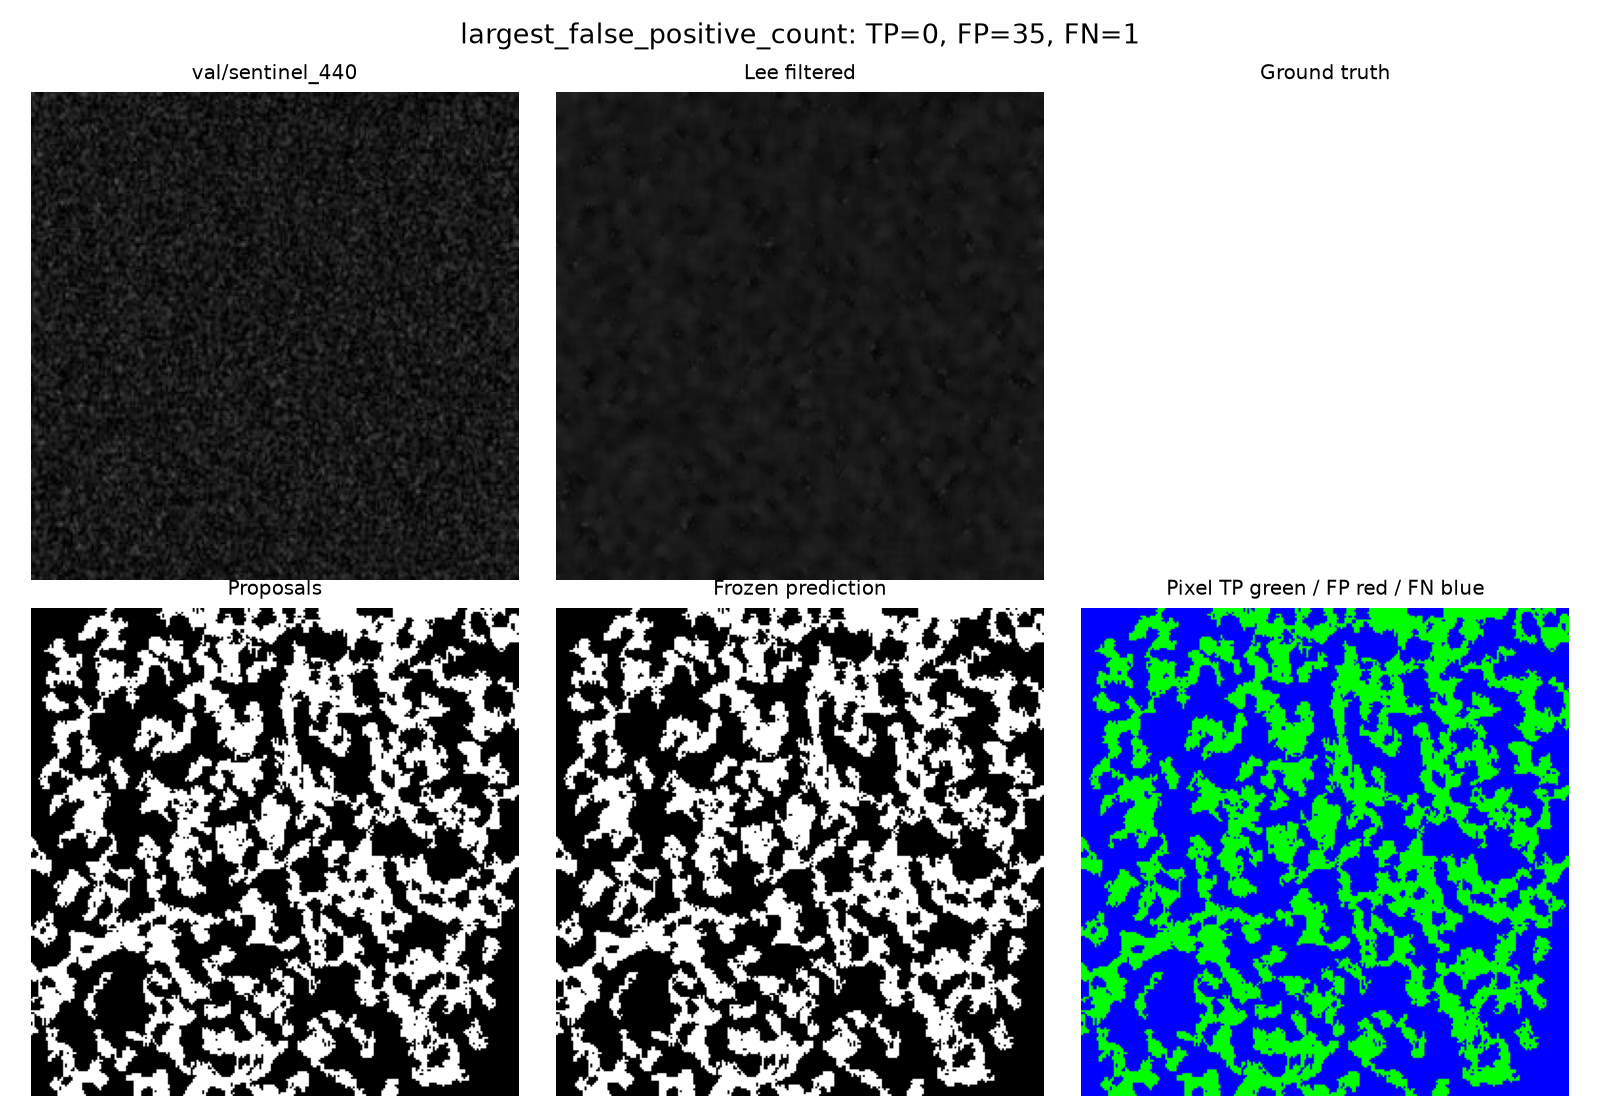

val/sentinel_25 largest_false_negative_count
Proposal: {'tp': 4, 'fp': 22, 'fn': 20, 'images': 1, 'empty_images': 0, 'intersection': 5121, 'union': 12632, 'predicted_pixels': 11265, 'truth_pixels': 6488, 'edge_gt': 8, 'edge_tp': 3, 'interior_gt': 16, 'interior_tp': 1} Final: {'tp': 4, 'fp': 10, 'fn': 20, 'images': 1, 'empty_images': 0, 'intersection': 4779, 'union': 11557, 'predicted_pixels': 9848, 'truth_pixels': 6488, 'edge_gt': 8, 'edge_tp': 3, 'interior_gt': 16, 'interior_tp': 1}
GT pixels absent from proposals: 1367 GT pixels removed by classifier: 342


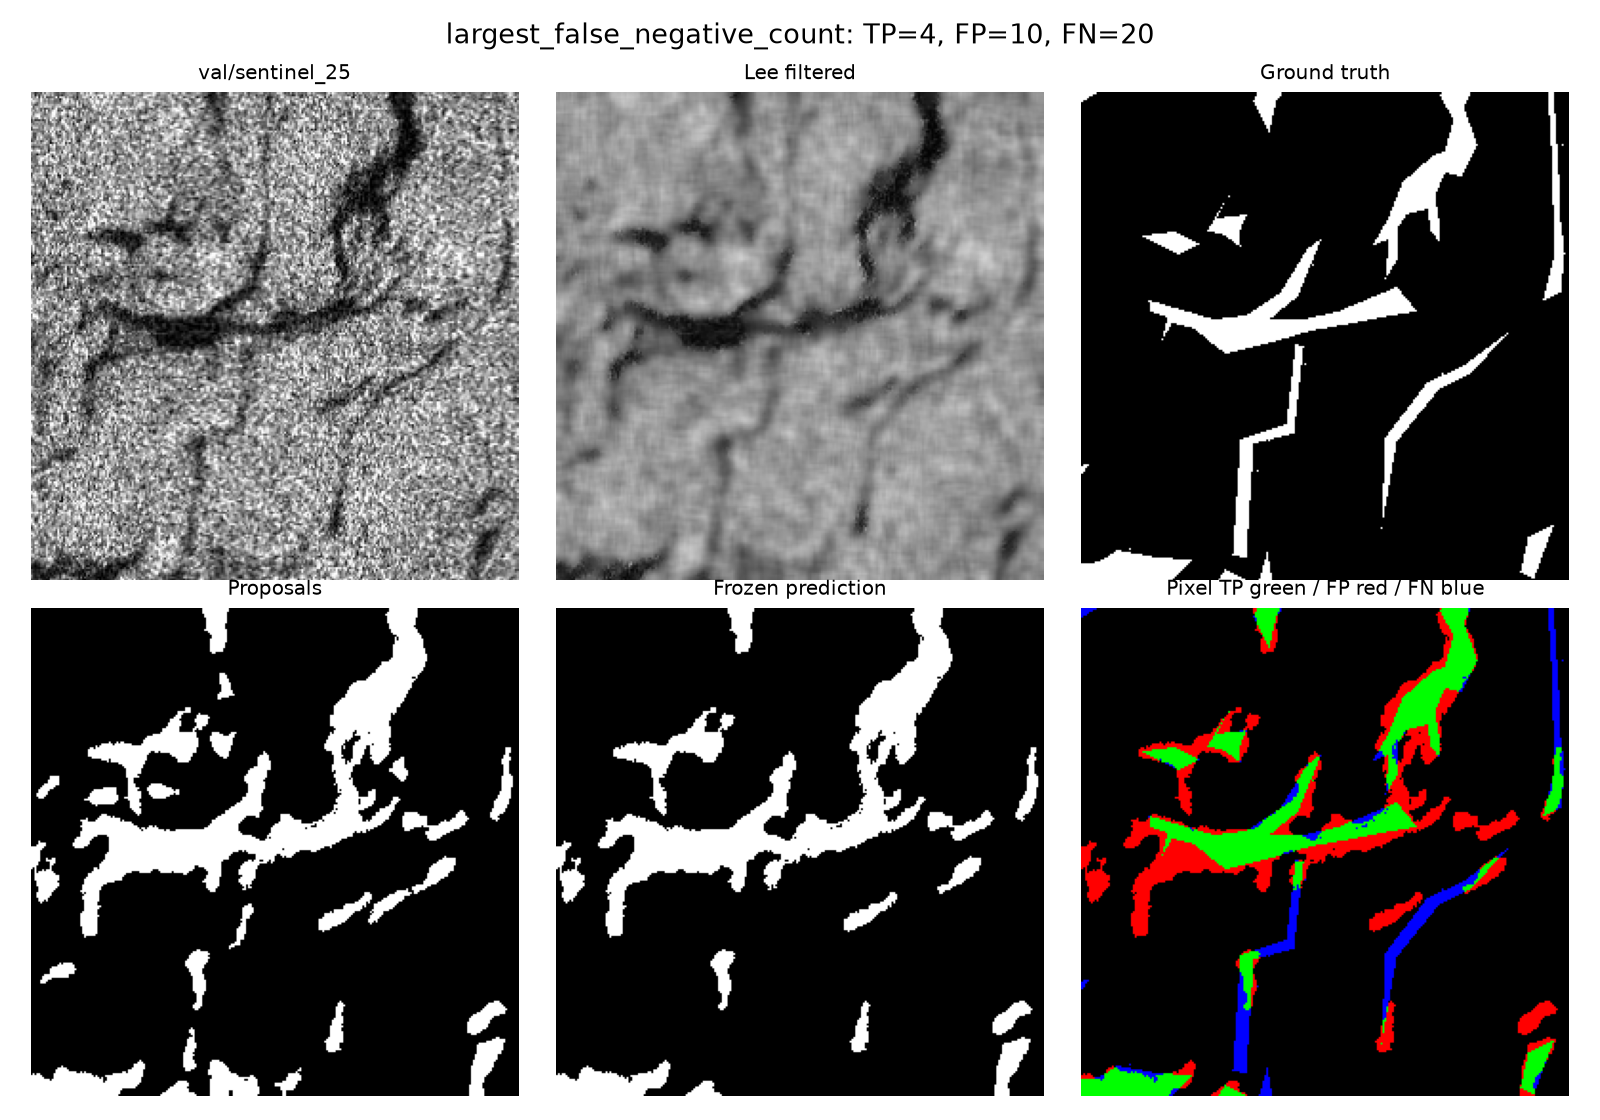

val/sentinel_591 largest_pixel_error
Proposal: {'tp': 0, 'fp': 40, 'fn': 1, 'images': 1, 'empty_images': 0, 'intersection': 27177, 'union': 65536, 'predicted_pixels': 27177, 'truth_pixels': 65536, 'edge_gt': 1, 'edge_tp': 0, 'interior_gt': 0, 'interior_tp': 0} Final: {'tp': 0, 'fp': 0, 'fn': 1, 'images': 1, 'empty_images': 0, 'intersection': 0, 'union': 65536, 'predicted_pixels': 0, 'truth_pixels': 65536, 'edge_gt': 1, 'edge_tp': 0, 'interior_gt': 0, 'interior_tp': 0}
GT pixels absent from proposals: 38359 GT pixels removed by classifier: 27177


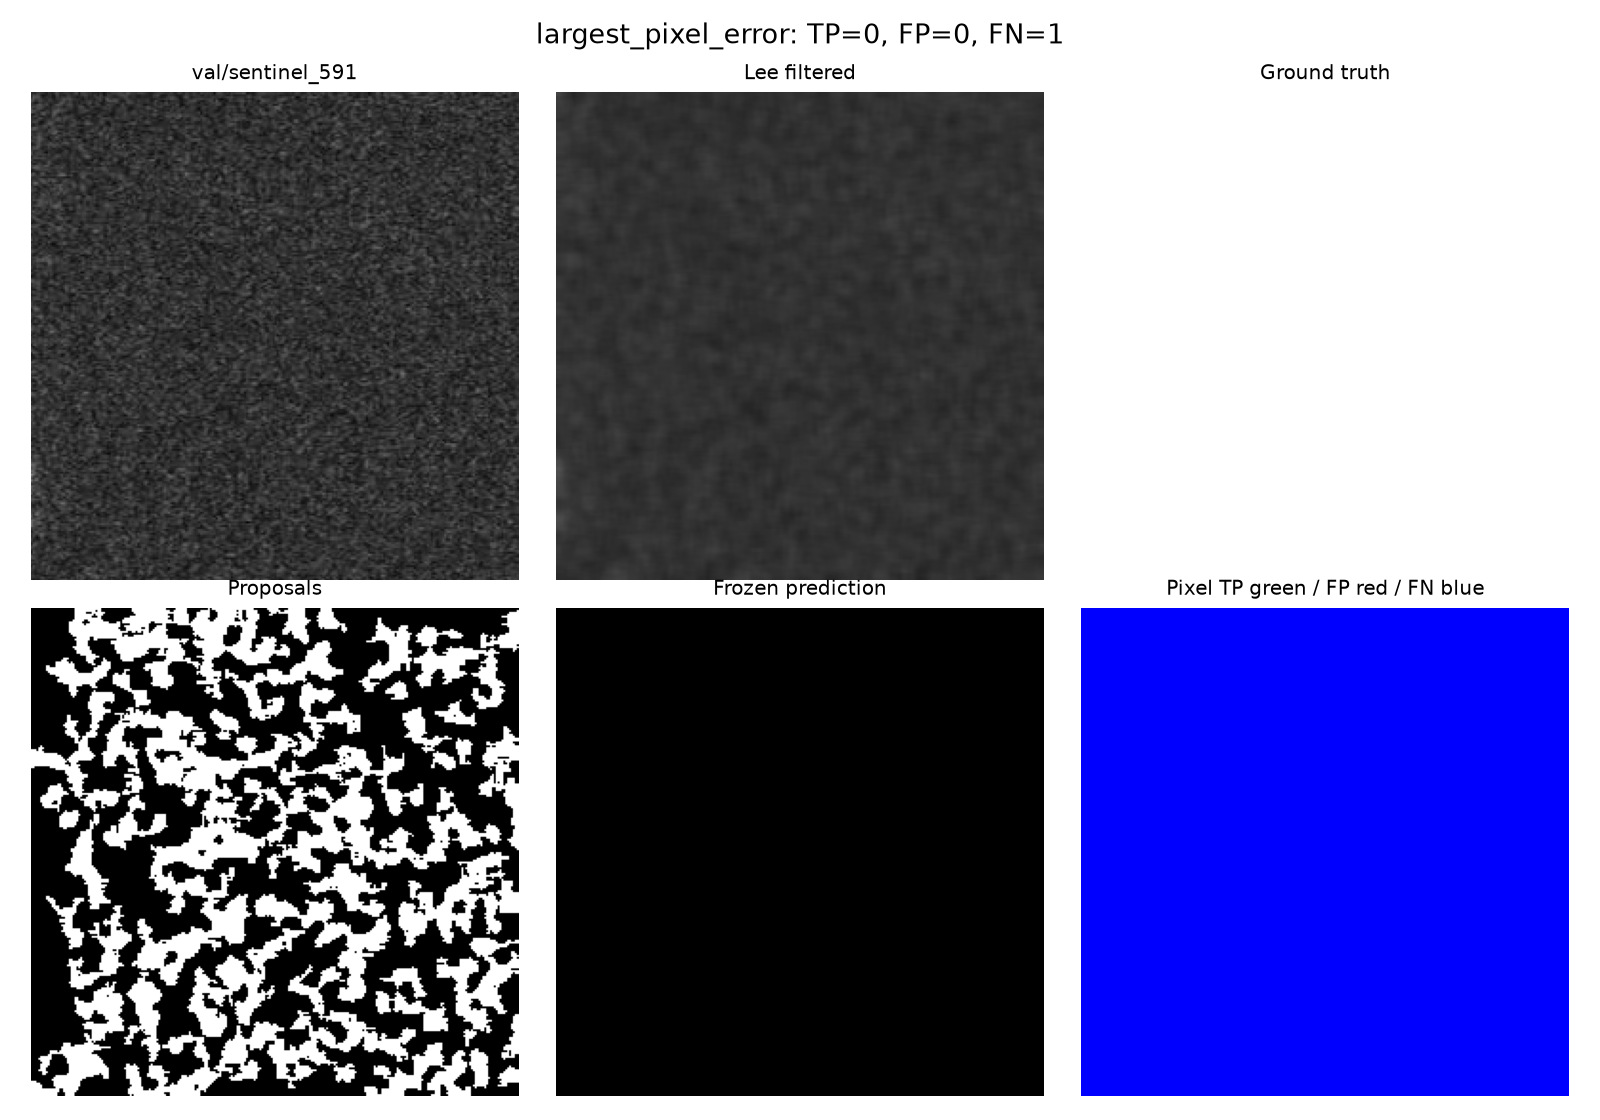

In [4]:
from IPython.display import Image as DiagnosticImage
diagnostics=load('diagnostics/diagnostics.json')
adaptive=load('adaptive/selected.json')
print('Nhánh thích nghi bổ sung (chỉ validation):',adaptive['config'],adaptive['kind'],adaptive['params'])
print('F1 adaptive validation:',adaptive['metrics']['f1'],'; không dùng kết quả test Otsu cho nhánh này.')
table([dict(experiment=k,micro_f1=v['micro']['f1'],**v['per_image']['f1']) for k,v in diagnostics['experiments'].items()],['experiment','micro_f1','mean','std_population','defined','undefined'])
for case in diagnostics['failure_cases']:
    print(case['id'],case['selection_rule'])
    print('Proposal:',case['proposal_counts'],'Final:',case['final_counts'])
    print('GT pixels absent from proposals:',case['truth_pixels_missing_from_proposals'],'GT pixels removed by classifier:',case['truth_pixels_removed_by_classifier'])
    display(DiagnosticImage(filename=str(OUT/'diagnostics'/case['figure'])))